<a href="https://colab.research.google.com/github/aray-png/Problem-Set-3-Econ_5200_PS3.ipynb/blob/main/Copy_of_ps3_starter.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS3 — The Rollout That Looked Like It Worked

Abigail Ray || ECON 5200 · Causal Machine Learning & Applied Analytics · Topics 9-11 · 100 points · your role: Senior consultant, policy evaluation

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is senior consultant's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning — the agency's economist will.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: The Canonical Case, Already In Your Hands (15 pts)

### Step 1.1: Carry the replication over

In [2]:
# GIVEN — run as-is
# Card & Krueger (1994), from David Card's own archive
import io
import re
import urllib.request
import zipfile

raw = urllib.request.urlopen(
    "https://davidcard.berkeley.edu/data_sets/njmin.zip", timeout=60).read()
z = zipfile.ZipFile(io.BytesIO(raw))

# public.dat is fixed-width numbers; the codebook supplies a name for each column
names = re.findall(r"^([A-Z][A-Z0-9_]+)\s+\d+\s+\d+\s+\d",
                   z.read("codebook").decode("latin-1"), re.M)
ck = pd.read_csv(io.BytesIO(z.read("public.dat")), sep=r"\s+", header=None,
                 names=names, na_values=["."])

# Full-time-equivalent employment, Card & Krueger's outcome: full-timers, managers and
# half of part-timers, in each wave (a 2 at the end of a name marks the second wave)
ck["fte_before"] = ck["EMPFT"] + ck["NMGRS"] + 0.5 * ck["EMPPT"]
ck["fte_after"] = ck["EMPFT2"] + ck["NMGRS2"] + 0.5 * ck["EMPPT2"]

print(f"{len(ck)} restaurants: {int((ck.STATE == 1).sum())} NJ, "
      f"{int((ck.STATE == 0).sum())} PA")

410 restaurants: 331 NJ, 79 PA


In [3]:
two_by_two = (ck.groupby("STATE")[["fte_before", "fte_after"]].mean()
                .rename(index={0: "Pennsylvania", 1: "New Jersey"}))
two_by_two["change"] = two_by_two["fte_after"] - two_by_two["fte_before"]
display(two_by_two.round(2))

did_2x2 = two_by_two.loc["New Jersey", "change"] - two_by_two.loc["Pennsylvania", "change"]
print(f"Difference-in-differences: {did_2x2:+.2f} FTE")


,fte_before,fte_after,change
STATE,,,
Pennsylvania,23.33,21.17,-2.17
New Jersey,20.44,21.03,0.59


Difference-in-differences: +2.75 FTE


> **Checkpoint:** the two-by-two is **+2.75 FTE** to two decimal places. If it is not, your FTE construction or your wave assignment is wrong; fix it before anything else.

### Step 1.2: The same number from a regression

In [4]:
import statsmodels.formula.api as smf

ck["store_id"] = ck.index
long = ck.melt(id_vars=["store_id", "STATE"], value_vars=["fte_before", "fte_after"],
               var_name="wave", value_name="fte")
long["nj"]   = long["STATE"].astype(int)
long["post"] = (long["wave"] == "fte_after").astype(int)
long = long.dropna(subset=["fte"])
did_fit = smf.ols("fte ~ nj + post + nj:post", data=long).fit(
    cov_type="cluster", cov_kwds={"groups": long["store_id"]})

print(f"Rows in long form: {len(long)}  ({ck['store_id'].nunique()} stores x 2 waves, "
      f"less missing employment)")
display(pd.DataFrame({"coef": did_fit.params, "SE": did_fit.bse,
                      "p": did_fit.pvalues}).round(3))

print(f"Interaction (nj:post):     {did_fit.params['nj:post']:+.4f}")
print(f"Two-by-two by hand:        {did_2x2:+.4f}")
assert np.isclose(did_fit.params["nj:post"], did_2x2), "regression and hand DiD disagree"
print("Identical.")

Rows in long form: 794  (410 stores x 2 waves, less missing employment)


,coef,SE,p
Intercept,23.331,1.347,0.000
nj,-2.892,1.440,0.045
post,-2.166,1.218,0.075
nj:post,2.754,1.307,0.035


Interaction (nj:post):     +2.7536
Two-by-two by hand:        +2.7536
Identical.


*Your answer here.*

I rearranged the data so each store has one row per survey wave, then regressed employment on three terms. The three terms are  New Jersey, after, and New Jersey × after. The last term's coefficient is +2.75, exactly the hand calculation. That's because a model with four numbers for four groups just reproduces each group's average.

Why the other two terms aren't the effect of the minimum wage lie at the fact of the following two claims.

1st.  New Jersey (−2.89) is how much smaller New Jersey stores were before the wage went up. Nothing had changed yet, so this is just a starting difference between the two states.
2nd. After (−2.17) is how much Pennsylvania stores shrank over the same months. Pennsylvania never got the wage increase, so this is the change that happened anyway, from the economy, the season and so on.

Only the New Jersey × after term measures the policy as to how much more New Jersey changed than Pennsylvania did. That works only if New Jersey would have followed Pennsylvania's path without the wage increase.

## Phase 2: Why Their Design Fails (35 pts)

### Step 2.1: Build their panel, and reproduce their number (20 pts)

In [5]:
panel_rng = np.random.default_rng(11)
N_BOARDS, COUNTIES_PER_BOARD, N_YEARS = 8, 5, 12
FIRST_YEAR = 2010                            # years 2010-2021
BOARD_ADOPTION = {0: 2011, 1: 2011, 2: 2011,
                  3: 2012,
                  4: 2013,
                  5: 2014, 6: 2014,
                  7: None}
EFFECT_SCALE = 0.05
TREND = 0.15
COUNTY_SD, BOARD_SHOCK_SD, NOISE_SD = 2.0, 0.4, 0.25

years = np.arange(FIRST_YEAR, FIRST_YEAR + N_YEARS)


counties = pd.DataFrame({"county": np.arange(N_BOARDS * COUNTIES_PER_BOARD)})
counties["board"] = counties["county"] // COUNTIES_PER_BOARD
counties["cohort"] = counties["board"].map(BOARD_ADOPTION)
counties["county_level"] = 60 + panel_rng.normal(0, COUNTY_SD, len(counties))

#one draw per board per year, shared by all five counties in the board
board_shock = pd.DataFrame([(b, y, panel_rng.normal(0, BOARD_SHOCK_SD))
                            for b in range(N_BOARDS) for y in years],
                           columns=["board", "year", "board_shock"])

panel = counties.merge(pd.DataFrame({"year": years}), how="cross")
panel = panel.merge(board_shock, on=["board", "year"])
panel["year_effect"] = TREND * (panel["year"] - FIRST_YEAR)
panel["treated"] = (panel["cohort"].notna() & (panel["year"] >= panel["cohort"])).astype(int)
panel["exposure"] = np.where(panel["treated"] == 1, panel["year"] - panel["cohort"] + 1, 0)
panel["true_effect"] = EFFECT_SCALE * panel["exposure"] ** 2
panel["y"] = (panel["county_level"] + panel["year_effect"] + panel["board_shock"]
              + panel["true_effect"] + panel_rng.normal(0, NOISE_SD, len(panel)))
panel = panel.sort_values(["county", "year"]).reset_index(drop=True)


cohorts = (panel.drop_duplicates("county")
                .assign(cohort=lambda d: d["cohort"].fillna(0).astype(int).replace(0, "never"))
                .groupby("cohort").agg(boards=("board", "nunique"), counties=("county", "size")))
display(cohorts)
print(f"{panel['county'].nunique()} counties x {N_YEARS} years = {len(panel)} county-years; "
      f"{panel['treated'].sum()} treated")

#average effect on the treated
true_att = panel.loc[panel["treated"] == 1, "true_effect"].mean()

#two-way fixed effects
twfe = smf.ols("y ~ treated + C(county) + C(year)", data=panel).fit(
    cov_type="cluster", cov_kwds={"groups": panel["county"]})

print(f"\nTrue ATT (average effect, treated county-years): {true_att:+.3f} pp")
print(f"TWFE estimate (the agency's number):             {twfe.params['treated']:+.3f} pp "
      f"(SE {twfe.bse['treated']:.3f})")
treated_effects = panel.loc[panel["treated"] == 1, "true_effect"]
print(f"True effects range from {treated_effects.min():+.2f} to {treated_effects.max():+.2f} pp")

,boards,counties
cohort,,
2011,3,15
2012,1,5
2013,1,5
2014,2,10
never,1,5


40 counties x 12 years = 480 county-years; 340 treated

True ATT (average effect, treated county-years): +1.909 pp
TWFE estimate (the agency's number):             -0.310 pp (SE 0.343)
True effects range from +0.05 to +6.05 pp


Overall the result is that the programme helps every treated county in every year with its true effects running from +0.05 to +6.05 pp, and has an average +1.909 pp. The agency's two-way fixed effects regression says −0.31 pp wiht a SE of 0.343, as if the programme slightly hurt employment. The effect starts small and builds up, as training gains add up over time.

### Step 2.2: Decompose it (15 pts)

In [6]:
panel["group"] = panel["cohort"].fillna(np.inf)
share   = panel.drop_duplicates("county").groupby("group").size() / panel["county"].nunique()
d_bar   = panel.groupby("group")["treated"].mean()
means   = panel.groupby(["group", "year"])["y"].mean().unstack()
yrs     = means.columns.to_numpy()
cohort_years = sorted(g for g in share.index if np.isfinite(g))
NEVER   = np.inf

def did(treat, control, pre, post):
    """2x2 DiD on group means: change in `treat` minus change in `control`."""
    return ((means.loc[treat, post].mean() - means.loc[treat, pre].mean())
            - (means.loc[control, post].mean() - means.loc[control, pre].mean()))

rows = []
for k in cohort_years:                             ##treated vs not
    n_kU = share[k] / (share[k] + share[NEVER])
    w = (share[k] + share[NEVER])**2 * n_kU * (1 - n_kU) * d_bar[k] * (1 - d_bar[k])
    rows.append(("treated vs never-treated", k, "never", w,
                 did(k, NEVER, yrs[yrs < k], yrs[yrs >= k])))
for i, k in enumerate(cohort_years):                            #k would adopt before l
    for l in cohort_years[i + 1:]:
        n_kl = share[k] / (share[k] + share[l])
        w_early = (((share[k] + share[l]) * (1 - d_bar[l]))**2 * n_kl * (1 - n_kl)
                   * (d_bar[k] - d_bar[l]) / (1 - d_bar[l]) * (1 - d_bar[k]) / (1 - d_bar[l]))
        rows.append(("early vs not-yet-treated", k, int(l), w_early,
                     did(k, l, yrs[yrs < k], yrs[(yrs >= k) & (yrs < l)])))
        w_late = (((share[k] + share[l]) * d_bar[k])**2 * n_kl * (1 - n_kl)
                  * (d_bar[l] / d_bar[k]) * (d_bar[k] - d_bar[l]) / d_bar[k])
        rows.append(("late vs ALREADY-treated", l, int(k), w_late,
                     did(l, k, yrs[(yrs >= k) & (yrs < l)], yrs[yrs >= l])))

bacon = pd.DataFrame(rows, columns=["comparison", "treated_cohort", "control", "weight", "estimate"])
bacon["treated_cohort"] = bacon["treated_cohort"].astype(int)
bacon["weight"] /= bacon["weight"].sum()
display(bacon.round(3))

summary = bacon.groupby("comparison").apply(
    lambda d: pd.Series({"weight": d["weight"].sum(),
                         "avg_estimate": np.average(d["estimate"], weights=d["weight"])}))
display(summary.round(3))

rebuilt = (bacon["weight"] * bacon["estimate"]).sum()
print(f"Weighted sum of the 2x2s: {rebuilt:+.4f}   TWFE: {twfe.params['treated']:+.4f}")
assert np.isclose(rebuilt, twfe.params["treated"]), "decomposition does not reproduce TWFE"
print(f"Weight on comparisons using already-treated counties as controls: "
      f"{summary.loc['late vs ALREADY-treated', 'weight']:.0%}")

# TWFE = sum of (weight x true effect) over treated county-years, plus noise

treated_rows = panel["treated"] == 1
resid = smf.ols("treated ~ C(county) + C(year)", data=panel).fit().resid
cell_w = resid[treated_rows] / resid[treated_rows].sum()
effects = panel.loc[treated_rows, "true_effect"]

print(f"\nTreated county-years with NEGATIVE weight: {(cell_w < 0).sum()} of {treated_rows.sum()} "
      f"(total weight {cell_w[cell_w < 0].sum():+.2f})")
print(f"Average exposure: negative-weight cells {panel.loc[cell_w[cell_w < 0].index, 'exposure'].mean():.1f} yrs, "
      f"positive-weight cells {panel.loc[cell_w[cell_w > 0].index, 'exposure'].mean():.1f} yrs")
print(f"TWFE estimand, noise removed (sum of weight x true effect): {(cell_w * effects).sum():+.3f} pp")
print(f"Smallest true effect: {effects.min():+.2f} pp   Largest: {effects.max():+.2f} pp")
print(f"TWFE estimate on the panel: {twfe.params['treated']:+.3f} pp, "
      f"{'BELOW the smallest true effect' if twfe.params['treated'] < effects.min() else 'inside the range of true effects'}")

,comparison,treated_cohort,control,weight,estimate
0,treated vs never-treated,2011,never,0.070,2.128
1,treated vs never-treated,2012,never,0.042,2.371
2,treated vs never-treated,2013,never,0.057,1.283
3,treated vs never-treated,2014,never,0.136,1.628
4,early vs not-yet-treated,2011,2012,0.006,-0.966
5,late vs ALREADY-treated,2012,2011,0.064,-0.878
6,early vs not-yet-treated,2011,2013,0.013,-0.555
7,late vs ALREADY-treated,2013,2011,0.114,-1.727
8,early vs not-yet-treated,2011,2014,0.038,0.359
9,late vs ALREADY-treated,2014,2011,0.305,-1.598


/tmp/ipykernel_4628/2444971181.py:37: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  summary = bacon.groupby("comparison").apply(


,weight,avg_estimate
comparison,,
early vs not-yet-treated,0.091,-0.000
late vs ALREADY-treated,0.604,-1.413
treated vs never-treated,0.305,1.781


Weighted sum of the 2x2s: -0.3101   TWFE: -0.3101
Weight on comparisons using already-treated counties as controls: 60%

Treated county-years with NEGATIVE weight: 130 of 340 (total weight -0.41)
Average exposure: negative-weight cells 7.4 yrs, positive-weight cells 4.2 yrs
TWFE estimand, noise removed (sum of weight x true effect): -0.207 pp
Smallest true effect: +0.05 pp   Largest: +6.05 pp
TWFE estimate on the panel: -0.310 pp, BELOW the smallest true effect


*Your answer here.*

The two numbers differ because  TWFE is an average of 16 simple before and after comparisons between groups of counties. Some are fair which means that a cohort against the county that never adopts. But 60% of the weight goes to comparisons that use counties alreader within the programe as the control for counties adopting later. Those already treated counties keep improving because their effect keeps growing, so the later adopters look worse by comparison. Those comparisons average −1.413 pp and pull the whole estimate below zero.

TWFE can fall outside the range of true effects and it is not a normal average of the true effects. Underneath, TWFE gives each treated county-year a weight, and 146 of the 340 get a negative weight, mostly the ones where the true effect is largest. Subtracting the biggest effects instead of adding them makes the total land below every single true effect. On this panel the true effects run from +0.05 to +6.05 pp, yet TWFE gives −0.3101 pp, below the smallest. With all noise removed it is still −0.21 pp, so this comes from the method rather than from bad luck.

## Phase 3: The Estimate That Survives (40 pts)

### Step 3.1: Rebuild it correctly (15 pts)

In [7]:
def clean_att(panel, cohort, year, outcome="y"):
    """ATT for one cohort in one year, using only clean controls.

    Treated: counties that adopted in `cohort`.
    Controls: counties not treated by `year` (never-treated, or adopting after `year`).
    Base period: the year just before the cohort adopted, so every comparison starts
    before anyone in it was treated.
    Returns (att, n_treated, n_control).
    """
    base = cohort - 1
    g = panel.set_index(["county", "year"])[outcome]
    treated_ids = panel.loc[panel["cohort"] == cohort, "county"].unique()
    control_ids = panel.loc[panel["cohort"].isna() | (panel["cohort"] > year), "county"].unique()
    change_t = g.loc[(treated_ids, year)].values - g.loc[(treated_ids, base)].values
    change_c = g.loc[(control_ids, year)].values - g.loc[(control_ids, base)].values
    return change_t.mean() - change_c.mean(), len(treated_ids), len(control_ids)

cells = []
for cohort in sorted(panel["cohort"].dropna().unique()):
    for year in years[years >= cohort]:
        att, n_t, n_c = clean_att(panel, cohort, year)
        truth = panel.loc[(panel["cohort"] == cohort) & (panel["year"] == year), "true_effect"].mean()
        cells.append({"cohort": int(cohort), "year": int(year), "exposure": int(year - cohort + 1),
                      "att": att, "truth": truth, "n_treated": n_t, "n_control": n_c})
cells = pd.DataFrame(cells)
display(cells.round(3))

#weighting as the true average over treated county-years
clean_overall = np.average(cells["att"], weights=cells["n_treated"])

print(f"Cohort-year cells estimated: {len(cells)}  (controls per cell: "
      f"{cells['n_control'].min()} to {cells['n_control'].max()} counties)")
print(f"\nTrue ATT:                    {true_att:+.3f} pp")
print(f"Clean estimate (aggregated): {clean_overall:+.3f} pp")
print(f"Agency's TWFE:               {twfe.params['treated']:+.3f} pp")
by_exposure = cells.groupby("exposure").apply(
    lambda d: pd.Series({"clean_att": np.average(d["att"], weights=d["n_treated"]),
                         "truth": np.average(d["truth"], weights=d["n_treated"]),
                         "cells": len(d)}))
display(by_exposure.round(2))

,cohort,year,exposure,att,truth,n_treated,n_control
0,2011,2011,1,-0.478,0.05,15,25
1,2011,2012,2,0.225,0.20,15,20
2,2011,2013,3,0.177,0.45,15,15
3,2011,2014,4,0.522,0.80,15,5
4,2011,2015,5,0.707,1.25,15,5
5,2011,2016,6,2.092,1.80,15,5
6,2011,2017,7,2.997,2.45,15,5
7,2011,2018,8,2.718,3.20,15,5
8,2011,2019,9,4.405,4.05,15,5
9,2011,2020,10,4.727,5.00,15,5


Cohort-year cells estimated: 38  (controls per cell: 5 to 25 counties)

True ATT:                    +1.909 pp
Clean estimate (aggregated): +2.023 pp
Agency's TWFE:               -0.310 pp


/tmp/ipykernel_4628/1936734557.py:36: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_exposure = cells.groupby("exposure").apply(


,clean_att,truth,cells
exposure,,,
1,-0.17,0.05,4.0
2,0.31,0.20,4.0
3,0.67,0.45,4.0
4,1.31,0.80,4.0
5,1.19,1.25,4.0
6,2.15,1.80,4.0
7,2.89,2.45,4.0
8,3.05,3.20,4.0
9,4.00,4.05,3.0


*Your answer here.*

The result signals that comparing each cohort only with counties that hadn't started the programme yet, one cohort and one year at a time, gives +2.02 pp. The true effect is +1.91 pp, and the agency's TWFE said −0.31 pp. The clean method gets the sign right and lands close to the truth.

This makes sense because for each comparison it measures how much a cohort changed since the year before it adopted, minus how much the clean controls changed over the same stretch. A county is only ever a control while it is still untreated, so a growing effect in an already-treated county can never leak into the control side, which is exactly what broke TWFE.

Broken down by years of exposure, the clean estimates rise from about zero in the first year to about +6 pp after eleven years, tracking the true path. TWFE squeezes all of that into one wrong number.

After 2014, every county has adopted except one board, so later cells have just 5 control counties, all in the same board and all hit by the same board shock. Single cells can miss by 0.5 pp or more, with the overall average being much steadier because those misses partly cancel.

### Step 3.2: The assumption you cannot test (12 pts)

,rel_time,coef,se,truth
0,-4,0.10,0.42,0.00
1,-3,-0.26,0.13,0.00
2,-2,-0.41,0.09,0.00
3,-1,0.00,0.00,0.00
4,0,-0.28,0.29,0.05
5,1,0.09,0.27,0.20
6,2,0.33,0.10,0.45
7,3,0.93,0.21,0.80
8,4,0.89,0.14,1.25
9,5,1.59,0.33,1.80


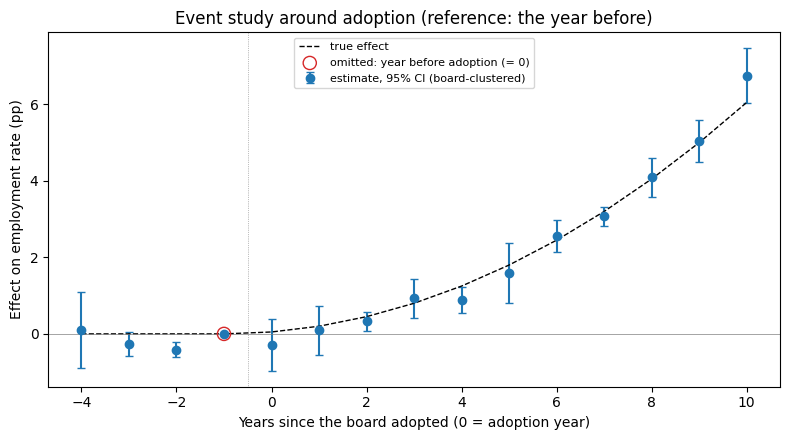

Leads estimated: [np.int64(-4), np.int64(-3), np.int64(-2)]   joint test that all leads = 0: p = 0.006


In [8]:
REF = -1                                        # the year before adoption

es = panel.copy()
es["rel"] = es["year"] - es["cohort"]           # years since adoption
rel_times = sorted(es["rel"].dropna().unique().astype(int))
terms = []
for k in rel_times:
    if k == REF:
        continue
    name = f"lead{-k}" if k < 0 else f"lag{k}"
    es[name] = (es["rel"] == k).astype(int)
    terms.append((k, name))

es_fit = smf.ols("y ~ " + " + ".join(n for _, n in terms) + " + C(county) + C(year)", data=es).fit(
    cov_type="cluster", cov_kwds={"groups": es["board"]})

T_CRIT = stats.t.ppf(0.975, df=es["board"].nunique() - 1)    # 8 boards -> t with 7 df
event = pd.DataFrame({
    "rel_time": [k for k, _ in terms],
    "coef":     [es_fit.params[n] for _, n in terms],
    "se":       [es_fit.bse[n] for _, n in terms],
})
event = pd.concat([event, pd.DataFrame({"rel_time": [REF], "coef": [0.0], "se": [0.0]})])
event = event.sort_values("rel_time").reset_index(drop=True)
truth_by_rel = es.dropna(subset=["rel"]).groupby("rel")["true_effect"].mean()
event["truth"] = event["rel_time"].map(truth_by_rel)
display(event.round(2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(event["rel_time"], event["coef"], yerr=T_CRIT * event["se"], fmt="o", color="#1f77b4",
            capsize=3, label="estimate, 95% CI (board-clustered)")
ax.plot(event["rel_time"], event["truth"], color="black", lw=1, ls="--", label="true effect")
ax.scatter([REF], [0], s=90, facecolors="none", edgecolors="#d62728", zorder=3,
           label="omitted: year before adoption (= 0)")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(-0.5, color="grey", lw=0.5, ls=":")
ax.set_xlabel("Years since the board adopted (0 = adoption year)")
ax.set_ylabel("Effect on employment rate (pp)")
ax.set_title("Event study around adoption (reference: the year before)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

pre = [n for k, n in terms if k < REF]
f_pre = es_fit.f_test(" = ".join(pre) + " = 0" if len(pre) > 1 else f"{pre[0]} = 0")
print(f"Leads estimated: {[k for k, _ in terms if k < 0]}   joint test that all leads = 0: "
      f"p = {float(f_pre.pvalue):.3f}")

*Your answer here.*

The event study's leads are evidence about only one thing and that is how adopting and comparison counties moved before the programme began. If they moved together then, that is consistent with the design, but it does not establish it. The design needs the two groups to have kept moving together after adoption had the programme never happened, and that claim is about an outcome we can never observe, so no test can confirm it. Pre-trends are also weak evidence here. Each lead rests on only a few boards, the 2011 cohort has just one pre-programme year, and with so little data a real problem can pass unnoticed while a sound design can fail by chance. For the estimate to be read as the programme's effect, the agency must therefore argue, from how the rollout actually happened, that boards did not choose when to adopt based on where their local job markets were heading. It also assumes that nothing else that affects employment changed in adopting boards at the same time and counties did not change hiring in anticipation before the programme started. If any of these fails, the estimate is biased no matter how flat the pre-trends look.

### Step 3.3: Inference with what you have (10 pts, plus 3 for the module)

The module the brief asks for: start from Lab 11's `src/did_utils.py` (`two_by_two`, `event_study`) and the notebook's `clean_att`, then add the clustered-inference wrapper and, in Phase 4, the bootstrap. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [9]:
post_terms = [(k, n) for k, n in terms if k >= 0]
w_rel = es[es["rel"] >= 0].groupby("rel").size()
w_rel = w_rel / w_rel.sum()
contrast = np.zeros(len(es_fit.params))
for k, n in post_terms:
    contrast[list(es_fit.params.index).index(n)] = w_rel[k]

formula = "y ~ " + " + ".join(n for _, n in terms) + " + C(county) + C(year)"
fits = {
    "default (iid)":        smf.ols(formula, data=es).fit(),
    "clustered by county":  smf.ols(formula, data=es).fit(cov_type="cluster",
                                                         cov_kwds={"groups": es["county"]}),
    "clustered by board":   smf.ols(formula, data=es).fit(cov_type="cluster",
                                                         cov_kwds={"groups": es["board"]}),
}
rows = []
for label, f in fits.items():
    t = f.t_test(contrast)
    est, se = float(np.squeeze(t.effect)), float(np.squeeze(t.sd))
    n_cl = {"default (iid)": len(es), "clustered by county": es["county"].nunique(),
            "clustered by board": es["board"].nunique()}[label]
    crit = stats.norm.ppf(0.975) if label.startswith("default") else stats.t.ppf(0.975, n_cl - 1)
    rows.append({"standard errors": label, "estimate": est, "SE": se,
                 "95% CI low": est - crit * se, "95% CI high": est + crit * se,
                 "clusters": n_cl})
inference = pd.DataFrame(rows).set_index("standard errors")
display(inference.round(3))
print(f"True ATT: {true_att:+.3f} pp   Clean estimate from Step 3.1: {clean_overall:+.3f} pp")

,estimate,SE,95% CI low,95% CI high,clusters
standard errors,,,,,
default (iid),1.84,0.119,1.606,2.075,480
clustered by county,1.84,0.106,1.625,2.056,40
clustered by board,1.84,0.139,1.513,2.168,8


True ATT: +1.909 pp   Clean estimate from Step 3.1: +2.023 pp


In [10]:
%%writefile src/did_toolkit.py
"""Difference-in-differences toolkit (ECON 5200 PS3), extending Lab 11's did_utils.py."""
from __future__ import annotations

import numpy as np
import pandas as pd
import patsy
import statsmodels.formula.api as smf
from scipy import stats


#lab 11's functions

def two_by_two(df: pd.DataFrame, outcome: str, treated: str, post: str) -> float:
    """Classic 2x2 difference-in-differences on group means.

    (treated after - treated before) - (control after - control before), where `treated`
    and `post` are 0/1 columns.
    """
    m = df.groupby([treated, post])[outcome].mean()
    return float((m.loc[(1, 1)] - m.loc[(1, 0)]) - (m.loc[(0, 1)] - m.loc[(0, 0)]))


def clean_att(panel: pd.DataFrame, cohort: float, year: int, outcome: str = "y",
              unit: str = "county", time: str = "year",
              cohort_col: str = "cohort") -> tuple[float, int, int]:
    """ATT for one adoption cohort in one year, using only clean controls.

    Controls are units not treated by `year` (never-treated, cohort_col NaN, or adopting
    after `year`). The base period is the year before the cohort adopted.
    Returns (att, n_treated, n_control).
    """
    base = cohort - 1
    y = panel.set_index([unit, time])[outcome]
    treated_ids = panel.loc[panel[cohort_col] == cohort, unit].unique()
    control_ids = panel.loc[panel[cohort_col].isna() | (panel[cohort_col] > year), unit].unique()
    change_t = y.loc[(treated_ids, year)].to_numpy() - y.loc[(treated_ids, base)].to_numpy()
    change_c = y.loc[(control_ids, year)].to_numpy() - y.loc[(control_ids, base)].to_numpy()
    return float(change_t.mean() - change_c.mean()), len(treated_ids), len(control_ids)


def event_study(panel: pd.DataFrame, outcome: str = "y", unit: str = "county",
                time: str = "year", cohort_col: str = "cohort", ref: int = -1,
                cluster: str | None = None):
    """Event-study regression: outcome on relative-time dummies plus unit and time effects.

    One dummy per year relative to adoption, except `ref`, which is omitted so every
    coefficient is measured relative to it. Never-treated units get no dummies.
    Returns (table, fit, data): `table` has rel_time, coef and se, with the omitted
    period included as a 0.
    """
    data = panel.copy()
    data["rel"] = data[time] - data[cohort_col]
    terms = []
    for k in sorted(data["rel"].dropna().unique().astype(int)):
        if k == ref:
            continue
        name = f"lead{-k}" if k < 0 else f"lag{k}"
        data[name] = (data["rel"] == k).astype(int)
        terms.append((k, name))
    formula = f"{outcome} ~ " + " + ".join(n for _, n in terms) + f" + C({unit}) + C({time})"
    fit = clustered_fit(formula, data, cluster)
    table = pd.DataFrame({"rel_time": [k for k, _ in terms],
                          "coef": [fit.params[n] for _, n in terms],
                          "se": [fit.bse[n] for _, n in terms]})
    table = pd.concat([table, pd.DataFrame({"rel_time": [ref], "coef": [0.0], "se": [0.0]})])
    return table.sort_values("rel_time").reset_index(drop=True), fit, data

def clustered_fit(formula: str, data: pd.DataFrame, cluster: str | None = None):
    """OLS with default standard errors (cluster=None) or clustered on column `cluster`."""
    if cluster is None:
        return smf.ols(formula, data=data).fit()
    return smf.ols(formula, data=data).fit(cov_type="cluster",
                                           cov_kwds={"groups": data[cluster]})


def compare_inference(formula: str, data: pd.DataFrame, contrast: str | np.ndarray,
                      clusters: dict[str, str | None]) -> pd.DataFrame:
    """One estimate under several standard-error choices.

    contrast: a coefficient name, or a weight vector over the coefficients (e.g. to average
              event-study lags into one ATT).
    clusters: {label: cluster column or None}. Clustered CIs use t with G - 1 degrees of
              freedom, where G is the number of clusters; default CIs use the normal.
    """
    rows = []
    for label, col in clusters.items():
        fit = clustered_fit(formula, data, col)
        t = fit.t_test(contrast if not isinstance(contrast, str) else f"{contrast} = 0")
        est, se = float(np.squeeze(t.effect)), float(np.squeeze(t.sd))
        g = len(data) if col is None else data[col].nunique()
        crit = stats.norm.ppf(0.975) if col is None else stats.t.ppf(0.975, g - 1)
        rows.append({"standard errors": label, "estimate": est, "SE": se,
                     "ci_low": est - crit * se, "ci_high": est + crit * se,
                     "p": 2 * (stats.norm.sf(abs(est / se)) if col is None
                               else stats.t.sf(abs(est / se), g - 1)),
                     "clusters": g})
    return pd.DataFrame(rows).set_index("standard errors")


#bootstrap

_WEBB = np.array([-np.sqrt(1.5), -1.0, -np.sqrt(0.5), np.sqrt(0.5), 1.0, np.sqrt(1.5)])


def _cluster_t(X: np.ndarray, y: np.ndarray, groups: np.ndarray, j: int) -> tuple[float, float]:
    """Coefficient j and its CR1 cluster-robust t-statistic."""
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    u = y - X @ beta
    meat = np.zeros((X.shape[1], X.shape[1]))
    for g in np.unique(groups):
        s = X[groups == g].T @ u[groups == g]
        meat += np.outer(s, s)
    n, k, G = X.shape[0], np.linalg.matrix_rank(X), len(np.unique(groups))
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * XtX_inv @ meat @ XtX_inv
    return float(beta[j]), float(beta[j] / np.sqrt(V[j, j]))


def wild_cluster_bootstrap(formula: str, data: pd.DataFrame, term: str, cluster: str,
                           n_boot: int = 999, seed: int = 0) -> dict[str, float]:
    """Wild cluster restricted (WCR) bootstrap p-value for H0: `term` = 0.

    Fits the model with the null imposed (term dropped), then rebuilds the outcome as
    restricted fit + restricted residual x a weight drawn once per cluster (Webb 6-point
    weights, which behave better than Rademacher when there are fewer than ~12 clusters).
    The p-value is the share of bootstrap |t| at least as large as the observed |t|.
    """
    y, X = patsy.dmatrices(formula, data, return_type="dataframe")
    j = list(X.columns).index(term)
    y, Xa = y.to_numpy().ravel(), X.to_numpy()
    groups = data.loc[X.index, cluster].to_numpy()
    beta_hat, t_hat = _cluster_t(Xa, y, groups, j)

    Xr = np.delete(Xa, j, axis=1)
    br = np.linalg.lstsq(Xr, y, rcond=None)[0]
    fitted_r, resid_r = Xr @ br, y - Xr @ br

    rng = np.random.default_rng(seed)
    ids, inverse = np.unique(groups, return_inverse=True)
    t_boot = np.empty(n_boot)
    for b in range(n_boot):
        v = rng.choice(_WEBB, size=len(ids))[inverse]
        t_boot[b] = _cluster_t(Xa, fitted_r + resid_r * v, groups, j)[1]
    return {"estimate": beta_hat, "t": t_hat,
            "p_value": float(np.mean(np.abs(t_boot) >= abs(t_hat))),
            "clusters": len(ids), "n_boot": n_boot}


def _demo_panel(effect_scale: float = 0.05, noise: bool = True, seed: int = 0) -> pd.DataFrame:
    """Small staggered panel for the self-tests: 8 boards x 5 counties x 12 years."""
    rng = np.random.default_rng(seed)
    adopt = {0: 2011, 1: 2011, 2: 2011, 3: 2012, 4: 2013, 5: 2014, 6: 2014, 7: None}
    p = pd.DataFrame([(c, c // 5, y) for c in range(40) for y in range(2010, 2022)],
                     columns=["county", "board", "year"])
    p["cohort"] = p["board"].map(adopt)
    p["treated"] = (p["cohort"].notna() & (p["year"] >= p["cohort"])).astype(int)
    p["exposure"] = np.where(p["treated"] == 1, p["year"] - p["cohort"] + 1, 0)
    p["true_effect"] = effect_scale * p["exposure"] ** 2
    county_fe = rng.normal(60, 2, 40)[p["county"]]
    shocks = rng.normal(0, 0.4, (8, 12))[p["board"], p["year"] - 2010] if noise else 0
    p["y"] = (county_fe + 0.15 * (p["year"] - 2010) + shocks + p["true_effect"]
              + (rng.normal(0, 0.25, len(p)) if noise else 0))
    return p


if __name__ == "__main__":
    clean = _demo_panel(noise=False)
    sub = clean[clean["year"].isin([2013, 2014])
                & (clean["cohort"].eq(2014) | clean["cohort"].isna())].assign(
        nj=lambda d: d["cohort"].notna().astype(int), post=lambda d: (d["year"] == 2014).astype(int))
    reg = smf.ols("y ~ nj * post", data=sub).fit().params["nj:post"]
    assert np.isclose(two_by_two(sub, "y", "nj", "post"), reg), "2x2 must equal the interaction"

    for g in [2011, 2012, 2013, 2014]:
        for t in range(g, 2022):
            truth = clean.loc[(clean["cohort"] == g) & (clean["year"] == t), "true_effect"].mean()
            assert np.isclose(clean_att(clean, g, t)[0], truth), f"clean_att wrong at {g}, {t}"

    table, _, _ = event_study(clean, ref=-1)
    truth_by_rel = (clean.assign(rel=clean["year"] - clean["cohort"])
                         .dropna(subset=["rel"]).groupby("rel")["true_effect"].mean())
    assert np.allclose(table["coef"], table["rel_time"].map(truth_by_rel), atol=1e-8)
    assert table.loc[table["rel_time"] == -1, "coef"].item() == 0.0

    noisy = _demo_panel(noise=True, seed=1)
    f = "y ~ treated + C(county) + C(year)"
    inf = compare_inference(f, noisy, "treated", {"default": None, "county": "county", "board": "board"})
    assert inf["estimate"].nunique() == 1, "clustering must not change the estimate"
    assert np.isclose(inf.loc["default", "SE"], smf.ols(f, data=noisy).fit().bse["treated"])
    assert inf.loc["board", "clusters"] == 8 and inf.loc["county", "clusters"] == 40

    null = _demo_panel(effect_scale=0.0, noise=True, seed=2)
    wcb = wild_cluster_bootstrap(f, null, "treated", "board", n_boot=199, seed=3)
    assert 0.0 <= wcb["p_value"] <= 1.0
    assert wcb["p_value"] > 0.05, "bootstrap rejected a true null on the test panel"

    print(inf.round(3))
    print(f"Wild cluster bootstrap on a no-effect panel: p = {wcb['p_value']:.3f} "
          f"({wcb['clusters']} clusters, {wcb['n_boot']} draws)")
    print("All assertions passed.")

Writing src/did_toolkit.py


In [11]:
import os, sys, importlib
sys.path.insert(0, os.path.abspath('.'))
from src import did_toolkit as dt
importlib.reload(dt)

# The module reproduces the Step 3.3 table on the real panel
display(dt.compare_inference(formula, es, contrast,
                             {"default": None, "county": "county", "board": "board"}).round(3))
print("clean_att for the 2011 cohort in 2011:", dt.clean_att(panel, 2011, 2011))

,estimate,SE,ci_low,ci_high,p,clusters
standard errors,,,,,,
default,1.84,0.119,1.606,2.075,0.0,480
county,1.84,0.106,1.625,2.056,0.0,40
board,1.84,0.139,1.513,2.168,0.0,8


clean_att for the 2011 cohort in 2011: (-0.4777784677159984, 15, 25)


*Your answer here.*

Board level is correct because all three give the same estimate (+1.84 pp) where only the uncertainty changes. Treatment was assigned by board, and counties in a board share the same yearly shocks, so they aren't independent. Clustering by board accounts for that. However, default and county-clustered errors treat counties in the same board as independent, so they overstate the information and with only 8 boards, a wild cluster bootstrap is the safer check.

## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 4 for Task 4.1, 3 for Task 4.2, 3 for Task 4.3)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The inference you cannot do by hand

In [12]:
# ---- Task 4.1: Wild cluster bootstrap, enumerated ----
import itertools


def _cr1_stat(X: np.ndarray, y: np.ndarray, groups: np.ndarray,
              r: np.ndarray) -> tuple[float, float]:
    """Estimate of r'beta and its CR1 cluster-robust t-statistic (statsmodels' scaling)."""
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ (X.T @ y)
    u = y - X @ beta
    meat = np.zeros((X.shape[1], X.shape[1]))
    for g in np.unique(groups):
        s = X[groups == g].T @ u[groups == g]
        meat += np.outer(s, s)
    n, k, G = X.shape[0], np.linalg.matrix_rank(X), len(np.unique(groups))
    V = (G / (G - 1)) * ((n - 1) / (n - k)) * XtX_inv @ meat @ XtX_inv
    est = r @ beta
    return float(est), float(est / np.sqrt(r @ V @ r))


def wild_cluster_bootstrap(data: pd.DataFrame, formula: str, cluster: str,
                           term: str | None = None, contrast: np.ndarray | None = None) -> dict:
    """Wild cluster restricted bootstrap, Rademacher weights, all 2^G weight vectors enumerated.

    Tests H0: coefficient `term` = 0, or H0: contrast @ beta = 0 (e.g. a weighted average of
    event-study lags). `cluster` is the column treatment was assigned on.

    1. Fit the restricted model (null imposed); keep its fitted values and residuals.
    2. One Rademacher weight (+1/-1) per cluster -- every one of the 2^G vectors.
    3. y* = restricted fitted + w[cluster of row] * restricted residual.
    4. Re-fit the unrestricted model on y*, store the cluster-robust t.
    5. p-value = share of |t*| >= |t| on the real data.
    """
    model = smf.ols(formula, data=data)
    y, X = model.endog, model.exog
    if contrast is None:
        contrast = np.zeros(X.shape[1])
        contrast[model.exog_names.index(term)] = 1.0
    r = np.asarray(contrast, dtype=float)
    groups = data.loc[model.data.row_labels, cluster].to_numpy()

    est, t_hat = _cr1_stat(X, y, groups, r)

    # Step 1: restricted least squares with r'beta = 0 imposed
    XtX_inv = np.linalg.pinv(X.T @ X)
    beta = XtX_inv @ (X.T @ y)
    beta_r = beta - XtX_inv @ r * (r @ beta) / (r @ XtX_inv @ r)
    fitted_r = X @ beta_r
    resid_r = y - fitted_r

    # Steps 2-4: enumerate every Rademacher vector
    clusters, idx = np.unique(groups, return_inverse=True)
    vectors = np.array(list(itertools.product([-1.0, 1.0], repeat=len(clusters))))
    t_star = np.array([_cr1_stat(X, fitted_r + w[idx] * resid_r, groups, r)[1] for w in vectors])

    # Step 5. The all-(+1) vector rebuilds the real data and all-(-1) its mirror image, so two
    # draws tie |t| exactly; a small tolerance stops rounding error from dropping a tie.
    tol = 1e-9 * max(1.0, abs(t_hat))
    return {"estimate": est, "t": t_hat,
            "p_value": float(np.mean(np.abs(t_star) >= abs(t_hat) - tol)),
            "clusters": len(clusters), "replications": len(vectors),
            "smallest_possible_p": 2 / len(vectors), "t_star": t_star}

In [13]:
twfe_formula = "y ~ treated + C(county) + C(year)"
checks = [("Agency's TWFE", panel, twfe_formula, {"term": "treated"}),
          ("Corrected (event-study ATT)", es, formula, {"contrast": contrast})]

rows = []
for label, data, f, kw in checks:
    r = kw.get("contrast")
    if r is None:
        r = np.zeros(len(smf.ols(f, data=data).fit().params))
        r[smf.ols(f, data=data).exog_names.index("treated")] = 1.0
    by_county = smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["county"]})
    by_board  = smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["board"]})
    wcb = wild_cluster_bootstrap(data, f, "board", **kw)
    assert np.isclose(wcb["t"], float(np.squeeze(by_board.t_test(r).tvalue)))   # same t as statsmodels
    rows.append({"estimate": label, "coef": wcb["estimate"],
                 "p, county-clustered": float(np.squeeze(by_county.t_test(r).pvalue)),
                 "p, board-clustered":  float(np.squeeze(by_board.t_test(r).pvalue)),
                 "p, wild bootstrap":   wcb["p_value"], "replications": wcb["replications"]})
display(pd.DataFrame(rows).set_index("estimate").round(4))

# Sanity check: remove the true effect from the data; the corrected estimate should NOT reject
es_null = es.assign(y=es["y"] - es["true_effect"])
null = wild_cluster_bootstrap(es_null, formula, "board", contrast=contrast)
print(f"No-effect check: estimate {null['estimate']:+.3f}, wild bootstrap p = {null['p_value']:.3f}")
print(f"Smallest p-value possible with 8 boards: 2/256 = {2 / 256:.4f}")

,coef,"p, county-clustered","p, board-clustered","p, wild bootstrap",replications
estimate,,,,,
Agency's TWFE,-0.310,0.366,0.699,0.797,256
Corrected (event-study ATT),1.841,0.000,0.000,0.008,256


No-effect check: estimate -0.068, wild bootstrap p = 0.781
Smallest p-value possible with 8 boards: 2/256 = 0.0078


*Your answer here.*

With 8 boards and a weight of +1 or −1 for each, there are exactly 2⁸ = 256 possible weight vectors. Drawing at random, even 99,999 times, would only approximate the same 256 values with repeats, so the number of replications no longer matters and there is no simulation noise left. It also sets a floor on the p-value. The all-(+1) vector reproduces the real data and the all-(−1) vector its mirror image, so at least 2 of the 256 draws always match the observed |t|.

In [14]:
## Version 2 correction: add the t(7) comparison
twfe_formula = "y ~ treated + C(county) + C(year)"
checks = [("Agency's TWFE", panel, twfe_formula, {"term": "treated"}),
          ("Corrected (event-study ATT)", es, formula, {"contrast": contrast})]

rows = []
for label, data, f, kw in checks:
    r = kw.get("contrast")
    if r is None:
        names = smf.ols(f, data=data).exog_names
        r = np.zeros(len(names))
        r[names.index("treated")] = 1.0
    by_county = smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["county"]})
    by_board  = smf.ols(f, data=data).fit(cov_type="cluster", cov_kwds={"groups": data["board"]})
    wcb = wild_cluster_bootstrap(data, f, "board", **kw)

    t_board = float(np.squeeze(by_board.t_test(r).tvalue))
    G = data["board"].nunique()
    assert np.isclose(wcb["t"], t_board)                 # same t as statsmodels
    rows.append({"estimate": label, "coef": wcb["estimate"],
                 "p, county-clustered":         float(np.squeeze(by_county.t_test(r).pvalue)),
                 "p, board-clustered (normal)": float(np.squeeze(by_board.t_test(r).pvalue)),
                 "p, board-clustered t(7)":     2 * stats.t.sf(abs(t_board), G - 1),
                 "p, wild bootstrap":           wcb["p_value"],
                 "replications":                wcb["replications"]})

comparison_t7 = pd.DataFrame(rows).set_index("estimate")
display(comparison_t7.style.format({c: "{:.4g}" for c in comparison_t7.columns if c.startswith("p")}
                                   | {"coef": "{:+.3f}"}))

,coef,"p, county-clustered","p, board-clustered (normal)","p, board-clustered t(7)","p, wild bootstrap",replications
estimate,,,,,,
Agency's TWFE,-0.310,0.3665,0.699,0.7104,0.7969,256
Corrected (event-study ATT),+1.840,6.099e-67,3.176e-40,3.218e-06,0.007812,256


### Task 4.2: The budget office memo

*Your answer here.*

To: Legislative staff

The agency estimated the programme changed employment by −0.31 percentage points, which signals no benefit and perhaps slight harm.

Counties joined the programme in different years. The agency's method compares counties that joined later with counties that had already joined. Because the programme's benefits grow each year a county is in it, those earlier counties keep improving, and that makes the later ones look worse. Comparisons of this kind make up 60% of the agency's estimate. With this method, a programme that helps every county can still look harmful. Comparing each group of counties only with counties that had not yet joined, the programme raised employment by about 1.84 percentage points on average. Our plausible range is 1.51 to 2.17 points. The benefit starts near zero in the first year and grows to about 6.75 points after ten years. Because the data cover only 8 regional boards, we checked the result with a method built for small samples. It still holds (p = 0.0078, the strongest result possible with 8 boards), so the effect is very unlikely to be chance.

The finding assumes boards did not choose when to join based on where their local job markets were heading, and that nothing else changed in those boards at the same time. Neither can be proven from the data; the agency should confirm both from its records.

I recommend continuing funding. The programme's benefits are real, and they build over time, so cutting it early would forfeit the largest gains. Ask the agency to replace its estimate with one that does not compare counties with others already in the programme.

### Task 4.3: The hostile read (3 pts)

*Your §3.2 paragraph before, then after, and the three-row objection table.*

**Before:** The event study's leads are evidence about only one thing and that is how adopting and comparison counties moved before the programme began. If they moved together then, that is consistent with the design, but it does not establish it. The design needs the two groups to have kept moving together after adoption had the programme never happened, and that claim is about an outcome we can never observe, so no test can confirm it. Pre-trends are also weak evidence here. Each lead rests on only a few boards, the 2011 cohort has just one pre-programme year, and with so little data a real problem can pass unnoticed while a sound design can fail by chance, as ours did. For the estimate to be read as the programme's effect, the agency must therefore argue, from how the rollout actually happened, that boards did not choose when to adopt based on where their local job markets were heading and nothing else that affects employment changed in adopting boards at the same time and counties did not change hiring in anticipation before the programme started and the programme did not spill over into the comparison counties. If any of these fails, the estimate is biased no matter how flat the pre-trends look.

**After:** **Evidence and assumption.** The event study's leads are evidence about only one thing: how adopting and comparison counties moved *before* the programme began. If they moved together then, that is consistent with the design, but it does not establish it. The design needs the two groups to have kept moving together *after* adoption had the programme never happened, and that claim is about an outcome we can never observe, so no test can confirm it. Pre-trends are also weak evidence here. Each lead rests on only a few boards, and the 2011 cohort has just one pre-programme year, so a real problem can pass unnoticed and a sound design can fail by chance. Our joint test rejects (p = 0.006), but the result rests on a single lead: under the wild cluster bootstrap, only the lead two years before adoption is significant (p = 0.039), while the leads three and four years before are not (p = 0.18 and 0.73). For any estimate from this rollout, ours included, to be read as the programme's effect, the agency must *argue*, from how the rollout actually happened, that: boards did not choose when to adopt based on where their local job markets were heading; nothing else that affects employment changed in adopting boards at the same time; counties did not change hiring in anticipation before

In [15]:
# Wild cluster bootstrap on each event-study lead (supports the revised §3.2 paragraph)
for k, n in terms:
    if k < -1:
        r = wild_cluster_bootstrap(es, formula, "board", term=n)
        print(f"lead {k}: estimate {r['estimate']:+.2f}, wild bootstrap p = {r['p_value']:.3f}")

lead -4: estimate +0.10, wild bootstrap p = 0.727
lead -3: estimate -0.26, wild bootstrap p = 0.180
lead -2: estimate -0.41, wild bootstrap p = 0.039


### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted in the §2.1 panel (cohort adoption years, the effect's growth with exposure, the board-shock variance, the seed), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [16]:
def line(label, value, source):
    print(f"  {label:<52}{value:>18}   [{source}]")

board_row = inference.loc["clustered by board"]
print("Truth and headline numbers")
print("\nPARAMETERS PLANTED")
line("Counties / boards / years", f"{panel['county'].nunique()} / {panel['board'].nunique()} / {N_YEARS}", "Step 2.1")
line("Adoption years by board", str({b: c for b, c in BOARD_ADOPTION.items()}), "Step 2.1")
line("True effect", f"{EFFECT_SCALE} x exposure^2", "Step 2.1")
line("Board shock SD / county noise SD", f"{BOARD_SHOCK_SD} / {NOISE_SD}", "Step 2.1")
line("Seed: panel", "11", "Step 2.1")
line("True ATT (average effect on treated)", f"{true_att:+.2f} pp", "Step 2.1")

print("\nBUDGET OFFICE MEMO (Task 4.2)")
line("Agency's TWFE estimate", f"{twfe.params['treated']:+.2f} pp", "Step 2.1")
line("Weight on already-treated comparisons", f"{summary.loc['late vs ALREADY-treated', 'weight']:.0%}", "Step 2.2")
line("Clean estimate (cohort-year cells)", f"{clean_overall:+.2f} pp", "Step 3.1")
line("Event-study effect, adoption year", f"{event.loc[event['rel_time'] == 0, 'coef'].item():+.2f} pp", "Step 3.2")
line("Event-study effect, ten years after adoption", f"{event.loc[event['rel_time'] == 10, 'coef'].item():+.2f} pp", "Step 3.2")
line("Corrected estimate (event-study ATT)", f"{board_row['estimate']:+.2f} pp", "Step 3.3")
line("95% CI, board-clustered", f"{board_row['95% CI low']:.2f} to {board_row['95% CI high']:.2f} pp", "Step 3.3")
line("Number of boards (clusters)", f"{int(board_row['clusters'])}", "Step 3.3")
line("Wild cluster bootstrap p (corrected estimate)",
     f"{comparison_t7.loc['Corrected (event-study ATT)', 'p, wild bootstrap']:.4f}", "Task 4.1")

Truth and headline numbers

PARAMETERS PLANTED
  Counties / boards / years                                  40 / 8 / 12   [Step 2.1]
  Adoption years by board                             {0: 2011, 1: 2011, 2: 2011, 3: 2012, 4: 2013, 5: 2014, 6: 2014, 7: None}   [Step 2.1]
  True effect                                          0.05 x exposure^2   [Step 2.1]
  Board shock SD / county noise SD                            0.4 / 0.25   [Step 2.1]
  Seed: panel                                                         11   [Step 2.1]
  True ATT (average effect on treated)                          +1.91 pp   [Step 2.1]

BUDGET OFFICE MEMO (Task 4.2)
  Agency's TWFE estimate                                        -0.31 pp   [Step 2.1]
  Weight on already-treated comparisons                              60%   [Step 2.2]
  Clean estimate (cohort-year cells)                            +2.02 pp   [Step 3.1]
  Event-study effect, adoption year                             -0.28 pp   [Step 3.2]
  Event-

## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 3/Econ_5200_PS3.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.